# Task 1: 2020 data only

### 0. Data Exploration

In [1]:
import pandas as pd
import torch

In [2]:
housing_df = pd.read_csv("data/housing_2020_train.csv")
housing_df.columns

Index(['median_income', 'population', 'households', 'housing_age', 'latitude',
       'longitude', 'median_house_value', 'fold'],
      dtype='str')

In [3]:
housing_df.describe()

,median_income,population,households,housing_age,latitude,longitude,median_house_value,fold
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,5.000000e+02,500.00000
mean,94308.232000,1570.264000,518.002000,48.66400,35.806872,-119.693055,6.263332e+05,2.00000
std,48242.421072,738.553042,234.607381,16.82621,2.158656,2.042241,4.003878e+05,1.41563
min,14175.000000,302.000000,123.000000,7.00000,32.576775,-124.193059,9.999000e+03,0.00000
25%,58699.250000,1023.250000,350.750000,38.00000,33.943271,-121.860720,3.524750e+05,1.00000
50%,83463.000000,1479.500000,471.500000,49.50000,34.530846,-119.080475,5.278500e+05,2.00000
75%,119123.750000,1933.500000,652.250000,61.25000,37.771637,-118.031144,7.747000e+05,3.00000
max,250001.000000,5075.000000,1981.000000,81.00000,41.921269,-114.657445,2.000001e+06,4.00000


In [4]:
housing_df.shape, housing_df.isna().sum()

((500, 8),
 median_income         0
 population            0
 households            0
 housing_age           0
 latitude              0
 longitude             0
 median_house_value    0
 fold                  0
 dtype: int64)

In [5]:
housing_df.value_counts(subset=housing_df.fold)

fold
2    100
4    100
1    100
3    100
0    100
Name: count, dtype: int64

In [6]:
import matplotlib.pyplot as plt

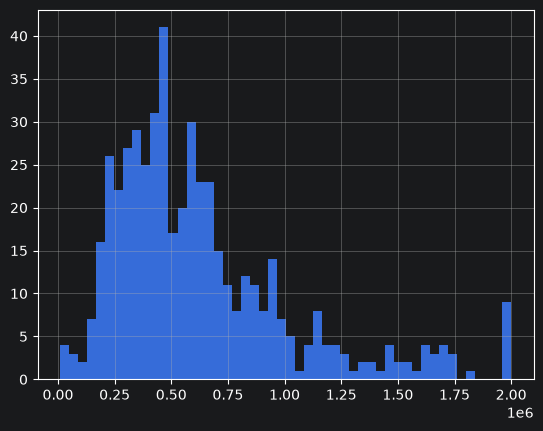

In [7]:
housing_df['median_house_value'].hist(bins=50)
plt.show()

In [8]:
housing_df.value_counts(subset=housing_df.median_house_value == 2000001), housing_df.value_counts(subset=housing_df.median_income == 250001), housing_df.value_counts(subset=housing_df.housing_age == 81)

(median_house_value
 False    491
 True       9
 Name: count, dtype: int64,
 median_income
 False    494
 True       6
 Name: count, dtype: int64,
 housing_age
 False    484
 True      16
 Name: count, dtype: int64)

### 1. Helper Functions

In [9]:
FEATURES = ['median_income', 'population', 'households', 'housing_age', 'latitude', 'longitude']
TARGET = 'median_house_value'
SEED = 42

In [10]:
import numpy as np

In [11]:
def split_data(dataset, fold_number=None):
    if fold_number is not None:
        is_train = dataset['fold'] != fold_number
        X_train, y_train, X_val, y_val = dataset[is_train][FEATURES], dataset[is_train][TARGET], dataset[~is_train][FEATURES], dataset[~is_train][TARGET]
        return X_train.to_numpy(dtype=np.float32), y_train.to_numpy(dtype=np.float32), X_val.to_numpy(dtype=np.float32), y_val.to_numpy(dtype=np.float32)
    else:
        X_train, y_train = dataset[FEATURES], dataset[TARGET]
        return X_train.to_numpy(dtype=np.float32), y_train.to_numpy(dtype=np.float32), None, None

In [12]:
class Standardizer:
    def __init__(self, X, y):
        self.mu_x = np.mean(X, axis=0)
        self.sigma_x = np.std(X, axis=0)
        self.mu_y = np.mean(y, axis=0)
        self.sigma_y = np.std(y, axis=0)

    def transform_X(self, X):
        return (X - self.mu_x) / self.sigma_x

    def transform_y(self, y):
        return (y - self.mu_y) / self.sigma_y

    def inverse(self, y_hat):
        return (y_hat * self.sigma_y) + self.mu_y

    @classmethod
    def from_stats(cls, mu_x, sigma_x, mu_y, sigma_y):
        # Build a standardizer from known statistics (e.g. the 1990 ones in mlp_1990.json)
        standardizer = cls.__new__(cls)
        standardizer.mu_x = np.asarray(mu_x, dtype=np.float32)
        standardizer.sigma_x = np.asarray(sigma_x, dtype=np.float32)
        standardizer.mu_y = np.float32(mu_y)
        standardizer.sigma_y = np.float32(sigma_y)
        return standardizer

In [13]:
import torch
from torch import nn

In [14]:
def build_model(p=0.0, seed=SEED):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(6, 64),
        nn.ReLU(),
        nn.Dropout(p),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Dropout(p),
        nn.Linear(64, 1)
    )

In [15]:
def train(model, X_train, y_train, X_val, y_val, lr, epochs, loss_type='MSE'):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if loss_type == 'MSE':
        loss_fn = nn.MSELoss()
    elif loss_type == 'L1':
        loss_fn = nn.L1Loss()
    else:
        raise ValueError('Invalid loss type')

    train_mae = []
    val_mae = []

    # Standardize the training data
    standardizer = Standardizer(X_train, y_train)
    X_train_standardized = torch.from_numpy(standardizer.transform_X(X_train))
    y_train_standardized = torch.from_numpy(standardizer.transform_y(y_train))
    y_train_dollars = torch.from_numpy(y_train)

    if X_val is not None:
        X_val_standardized = torch.from_numpy(standardizer.transform_X(X_val))
        y_val_dollars = torch.from_numpy(y_val)

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_hat = model(X_train_standardized).squeeze(1)
        loss = loss_fn(y_hat, y_train_standardized)
        loss.backward()
        optimizer.step()

        #Measure the error
        model.eval()
        with torch.no_grad():
            y_training_standardized_hat = model(X_train_standardized).squeeze(1)
            y_train_hat = standardizer.inverse(y_training_standardized_hat)
            train_mae.append(torch.mean(torch.abs(y_train_hat - y_train_dollars)).item())
            if X_val is not None:
                y_val_standardized_hat = model(X_val_standardized).squeeze(1)
                y_val_hat = standardizer.inverse(y_val_standardized_hat)
                val_mae.append(torch.mean(torch.abs(y_val_hat - y_val_dollars)).item())

    return train_mae, val_mae, standardizer


### 1.1 Testing Model

In [16]:
X_train, y_train, X_val, y_val = split_data(housing_df, 0)
model = build_model()

train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, epochs=2000, lr=1e-3)

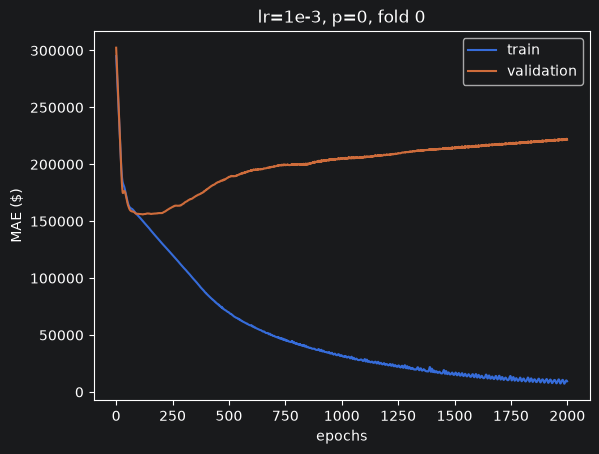

In [17]:
plt.plot(train_mae, label="train"), plt.plot(val_mae, label="validation"), plt.legend();
plt.xlabel("epochs")
plt.ylabel("MAE ($)")
plt.title("lr=1e-3, p=0, fold 0")

plt.savefig("figures/1-1.png", dpi=200, bbox_inches="tight")

### A1
- Data: split_data(housing_df, 0)
- Model: build_model(p=0, seed=SEED), a fresh model for each rate with the same seed, so every rate starts from identical weights
- Loss: MSE
- Epochs: 2000
- Only changing: lr

In [18]:
lrs = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
X_train, y_train, X_val, y_val = split_data(housing_df, 0)

output = {}

for lr in lrs:
    model = build_model()
    train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, epochs=2000, lr=lr)
    output[lr] = train_mae, val_mae

In [19]:
def plot_curves(ax, train_mae, val_mae, title, ylim=(0, 350_000), log=False):
    ax.plot(train_mae, label="train")
    ax.plot(val_mae, label="validation")
    best = int(np.argmin(val_mae))
    ax.axvline(best, ls="--", lw=0.8, color="grey")   # best validation epoch
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE ($)")
    if log:
        ax.set_yscale("log")
    else:
        ax.set_ylim(*ylim)

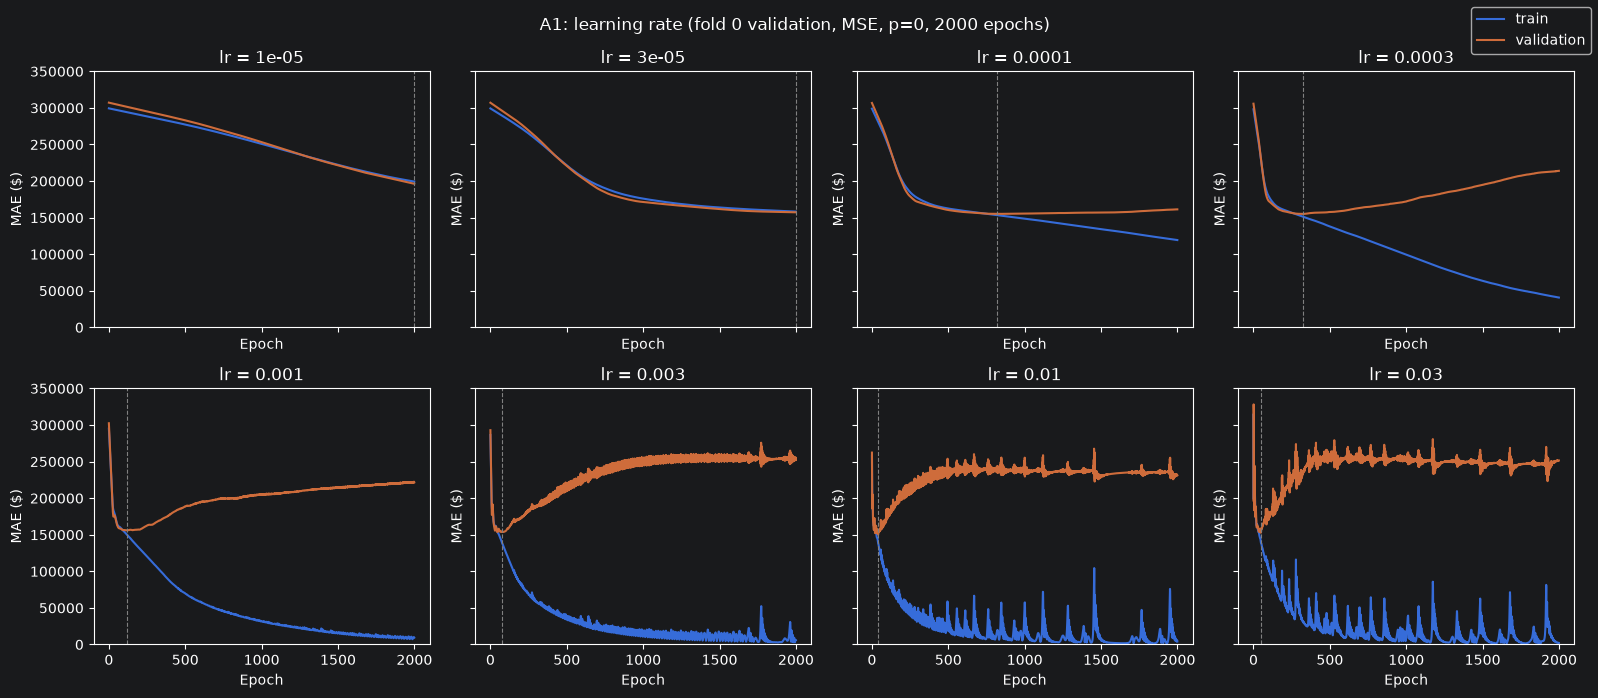

In [20]:
lrs = list(output.keys())
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.ravel()

for ax, lr in zip(axes, lrs):
    tr, va = output[lr]
    plot_curves(ax, tr, va, title=f"lr = {lr:g}")

for ax in axes[len(lrs):]:          # hide unused panels
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("A1: learning rate (fold 0 validation, MSE, p=0, 2000 epochs)")
fig.tight_layout()
fig.savefig("figures/a1_learning_rates.png", dpi=200, bbox_inches="tight")
plt.show()

### A2

- Data: fold 0 for validation, folds 1–4 for training
- lr: 1e-3, the rate chosen in A1
- Epochs: 2000
- Loss: MSE
- Seed: same SEED for every p, so initial weights are identical
- Only changing: p

In [21]:
ps = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]

X_train, y_train, X_val, y_val = split_data(housing_df, 0)

output = {}

for p in ps:
    model = build_model(p=p)
    train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, epochs=2000, lr=1e-3)
    output[p] = train_mae, val_mae

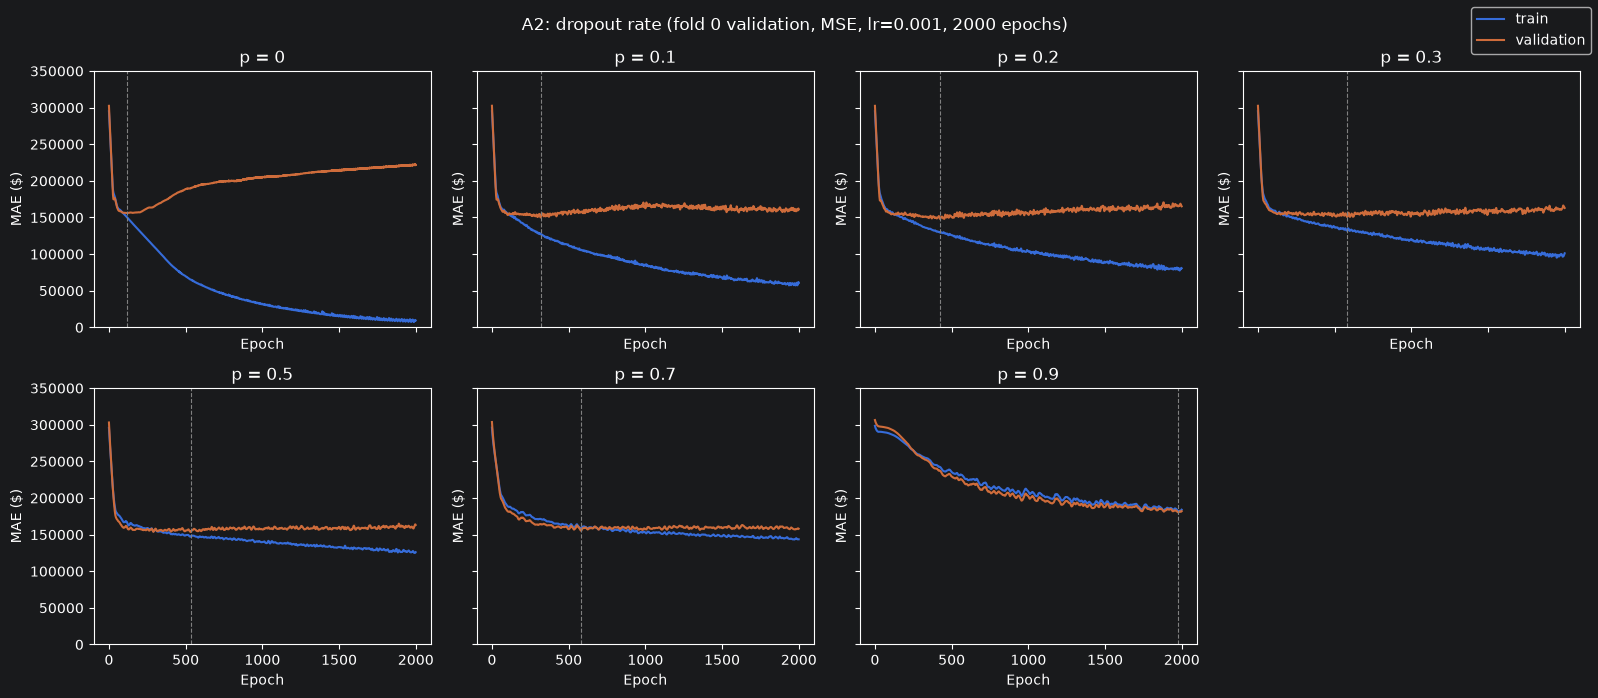

In [22]:
lrs = list(output.keys())
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.ravel()

for ax, p in zip(axes, ps):
    tr, va = output[p]
    plot_curves(ax, tr, va, title=f"p = {p:g}")

for ax in axes[len(lrs):]:          # hide unused panels
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("A2: dropout rate (fold 0 validation, MSE, lr=0.001, 2000 epochs)")
fig.tight_layout()
fig.savefig("figures/a2_dropout_rates.png", dpi=200, bbox_inches="tight")
plt.show()

### A3

In [23]:
def cross_validate(p, lr, epochs, loss_type, pretrained=False):
    train_curves, val_curves = [], []
    for k in range(5):
        X_train, y_train, X_val, y_val = split_data(housing_df, k)
        model = build_model(p=p)
        if pretrained:
            load_1990_weights(model)   # defined in Task 1B
        train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, lr, epochs, loss_type=loss_type)
        train_curves.append(train_mae)
        val_curves.append(val_mae)

    train_curves = np.array(train_curves)
    val_curves = np.array(val_curves)
    final_val = val_curves[:, -1]

    return train_curves, val_curves, final_val

In [24]:
ps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

output = {}

for p in ps:
    train_curves, val_curves, final_val = cross_validate(p, lr=1e-3, epochs=2000, loss_type="MSE")
    output[p] = train_curves, val_curves, final_val

In [25]:
rows = []
for p, (train_curves, val_curves, final_val) in output.items():
    final_train = train_curves[:, -1]
    row = {"p": p}
    for k in range(5):
        row[f"fold {k}"] = final_val[k]
    row["mean"] = final_val.mean()
    row["s.d."] = final_val.std(ddof=1)               # sample s.d. across the 5 folds
    row["s.e."] = row["s.d."] / np.sqrt(len(final_val))
    row["mean train"] = final_train.mean()
    row["gap"] = row["mean"] - row["mean train"]
    rows.append(row)

a3_table = pd.DataFrame(rows).set_index("p").round(0)

# Fold-by-fold comparison against p = 0: on how many folds does each p beat no dropout?
base = output[0.0][2]
a3_table["folds beating p=0"] = [int((output[p][2] < base).sum()) for p in a3_table.index]

a3_table


,fold 0,fold 1,fold 2,fold 3,fold 4,mean,s.d.,s.e.,mean train,gap,folds beating p=0
p,,,,,,,,,,,
0.0,221682.0,206629.0,259030.0,259448.0,245113.0,238380.0,23466.0,10494.0,11416.0,226964.0,0
0.1,161028.0,172442.0,171264.0,176346.0,173320.0,170880.0,5820.0,2603.0,58820.0,112060.0,5
0.2,165278.0,176684.0,178208.0,170891.0,174479.0,173108.0,5170.0,2312.0,80860.0,92248.0,5
0.3,163049.0,177032.0,172653.0,177634.0,166502.0,171374.0,6440.0,2880.0,99516.0,71858.0,5
0.4,157082.0,189613.0,171187.0,174191.0,157573.0,169929.0,13462.0,6020.0,114166.0,55763.0,5
0.5,163202.0,186686.0,173894.0,174370.0,158543.0,171339.0,10968.0,4905.0,124419.0,46920.0,5
0.6,160562.0,180774.0,172958.0,178287.0,153628.0,169242.0,11702.0,5233.0,134245.0,34996.0,5
0.7,158049.0,178636.0,175833.0,181348.0,154755.0,169724.0,12372.0,5533.0,143077.0,26647.0,5


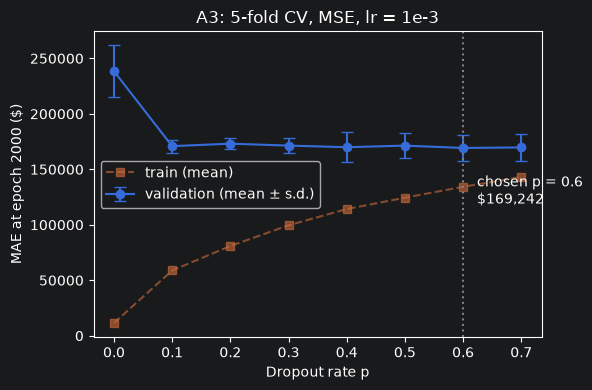

In [26]:
ps = a3_table.index.to_numpy()
means = a3_table["mean"].to_numpy()
sds = a3_table["s.d."].to_numpy()
best_p = ps[np.argmin(means)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(ps, means, yerr=sds, fmt="o-", capsize=4, label="validation (mean ± s.d.)")

# Optional: show training MAE for the shrinking gap
ax.plot(ps, a3_table["mean train"], "s--", alpha=0.6, label="train (mean)")

# Highlight the chosen p
ax.axvline(best_p, ls=":", color="grey")
ax.annotate(f"chosen p = {best_p:g}\n${means.min():,.0f}",
            xy=(best_p, means.min()), xytext=(10, -40), textcoords="offset points")

ax.set_xlabel("Dropout rate p")
ax.set_ylabel("MAE at epoch 2000 ($)")
ax.set_xticks(ps)
ax.set_title("A3: 5-fold CV, MSE, lr = 1e-3")
ax.legend()
fig.tight_layout()
fig.savefig("figures/a3_cv_dropout.png", dpi=200, bbox_inches="tight")
plt.show()

### A4

In [27]:
ps = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]

X_train, y_train, X_val, y_val = split_data(housing_df, 0)

output_l1 = {}

for p in ps:
    model = build_model(p=p)
    train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, epochs=2000, lr=1e-3, loss_type="L1")
    output_l1[p] = train_mae, val_mae

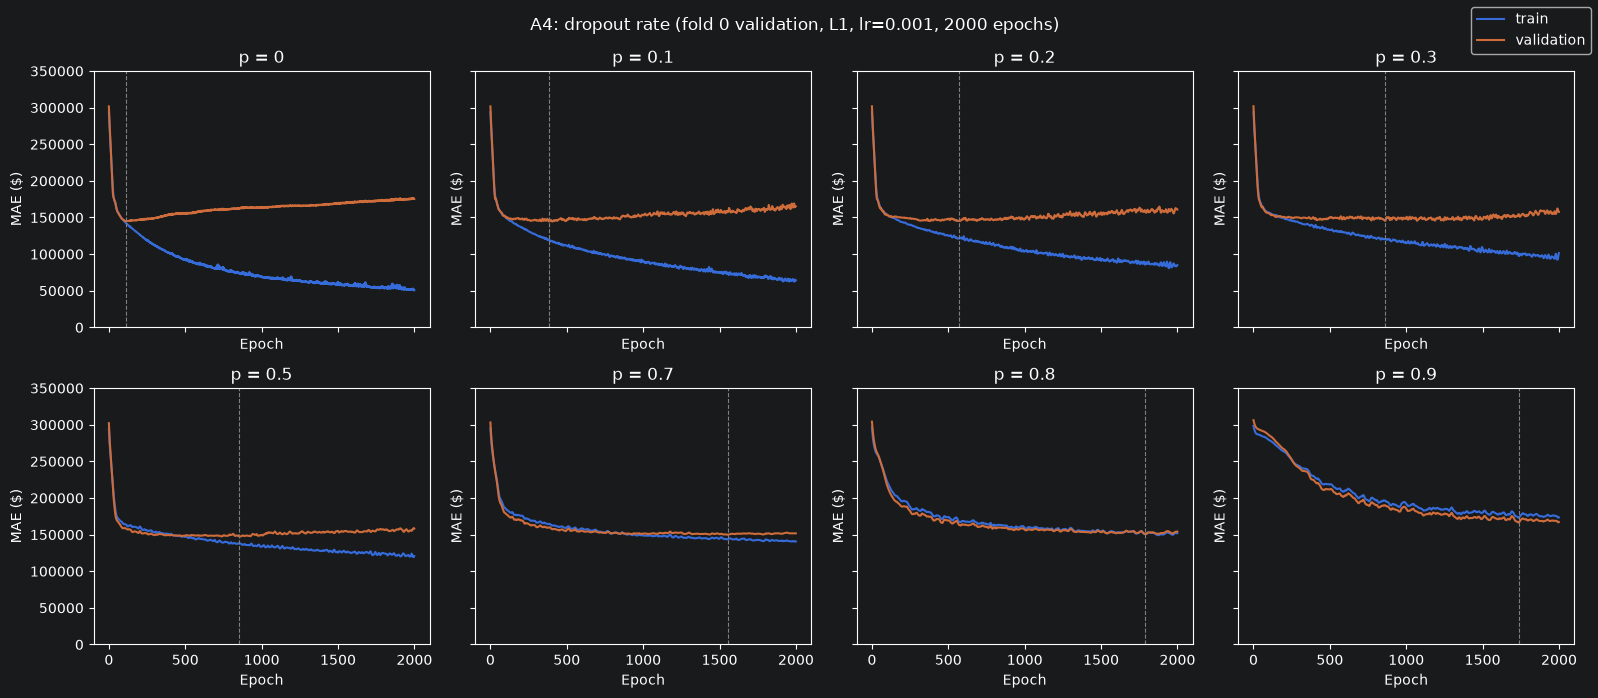

In [28]:
lrs = list(output_l1.keys())
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.ravel()

for ax, p in zip(axes, ps):
    tr, va = output_l1[p]
    plot_curves(ax, tr, va, title=f"p = {p:g}")

for ax in axes[len(lrs):]:          # hide unused panels
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("A4: dropout rate (fold 0 validation, L1, lr=0.001, 2000 epochs)")
fig.tight_layout()
fig.savefig("figures/a4_fold0_l1.png", dpi=200, bbox_inches="tight")
plt.show()

In [29]:
ps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

output_l1 = {}

for p in ps:
    train_curves, val_curves, final_val = cross_validate(p, lr=1e-3, epochs=2000, loss_type="L1")
    output_l1[p] = train_curves, val_curves, final_val

In [30]:
rows = []
for p, (train_curves, val_curves, final_val) in output_l1.items():
    final_train = train_curves[:, -1]
    row = {"p": p}
    for k in range(5):
        row[f"fold {k}"] = final_val[k]
    row["mean"] = final_val.mean()
    row["s.d."] = final_val.std(ddof=1)               # sample s.d. across the 5 folds
    row["s.e."] = row["s.d."] / np.sqrt(len(final_val))
    row["mean train"] = final_train.mean()
    row["gap"] = row["mean"] - row["mean train"]
    rows.append(row)

a4_table_1 = pd.DataFrame(rows).set_index("p").round(0)

# Fold-by-fold comparison against p = 0: on how many folds does each p beat no dropout?
base = output_l1[0.0][2]
a4_table_1["folds beating p=0"] = [int((output_l1[p][2] < base).sum()) for p in a4_table_1.index]

a4_table_1


,fold 0,fold 1,fold 2,fold 3,fold 4,mean,s.d.,s.e.,mean train,gap,folds beating p=0
p,,,,,,,,,,,
0.0,175403.0,176370.0,205013.0,190692.0,200017.0,189499.0,13452.0,6016.0,53960.0,135539.0,0
0.1,165279.0,162361.0,182364.0,163498.0,160837.0,166868.0,8813.0,3941.0,67251.0,99617.0,5
0.2,160773.0,162886.0,171001.0,160158.0,165640.0,164092.0,4418.0,1976.0,83060.0,81032.0,5
0.3,157688.0,163857.0,169315.0,165666.0,165924.0,164490.0,4283.0,1916.0,99832.0,64658.0,5
0.4,157315.0,165159.0,160687.0,174099.0,157629.0,162978.0,6971.0,3117.0,113808.0,49170.0,5
0.5,158246.0,167350.0,160984.0,174907.0,160722.0,164442.0,6748.0,3018.0,122915.0,41527.0,5
0.6,153435.0,170588.0,164893.0,176964.0,162018.0,165579.0,8879.0,3971.0,130587.0,34992.0,5
0.7,151725.0,171525.0,152682.0,181666.0,153605.0,162241.0,13602.0,6083.0,139473.0,22767.0,5
0.8,154086.0,172069.0,154758.0,187655.0,153321.0,164378.0,15180.0,6789.0,149664.0,14714.0,5


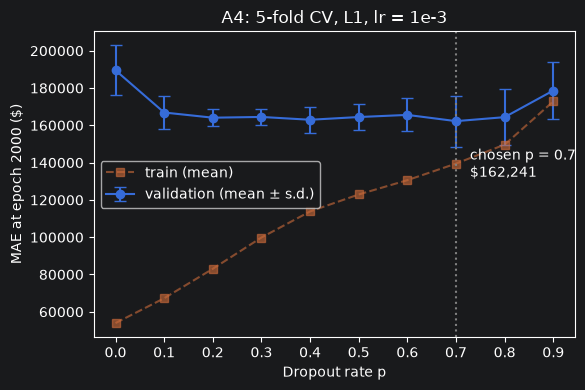

In [31]:
ps = a4_table_1.index.to_numpy()
means = a4_table_1["mean"].to_numpy()
sds = a4_table_1["s.d."].to_numpy()
best_p = ps[np.argmin(means)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(ps, means, yerr=sds, fmt="o-", capsize=4, label="validation (mean ± s.d.)")

# Optional: show training MAE for the shrinking gap
ax.plot(ps, a4_table_1["mean train"], "s--", alpha=0.6, label="train (mean)")

# Highlight the chosen p
ax.axvline(best_p, ls=":", color="grey")
ax.annotate(f"chosen p = {best_p:g}\n${means.min():,.0f}",
            xy=(best_p, means.min()), xytext=(10, -40), textcoords="offset points")

ax.set_xlabel("Dropout rate p")
ax.set_ylabel("MAE at epoch 2000 ($)")
ax.set_xticks(ps)
ax.set_title("A4: 5-fold CV, L1, lr = 1e-3")
ax.legend()
fig.tight_layout()
fig.savefig("figures/a4_cv_dropout_l1.png", dpi=200, bbox_inches="tight")
plt.show()

In [32]:
def cv_table(results, ref_p=0.0):
    rows = []
    base = results[ref_p][2]
    for p, (train_curves, val_curves, final_val) in results.items():
        final_val = np.asarray(final_val)
        sd = final_val.std(ddof=1)
        rows.append({
            "p": p,
            **{f"fold {k}": final_val[k] for k in range(len(final_val))},
            "mean": final_val.mean(),
            "s.d.": sd,
            "s.e.": sd / np.sqrt(len(final_val)),
            "mean train": np.asarray(train_curves)[:, -1].mean(),
            "folds beating p=0": int((final_val < base).sum()),
        })
    table = pd.DataFrame(rows).set_index("p")
    table["gap"] = table["mean"] - table["mean train"]
    return table.round(0)

a3_table = cv_table(output)      # MSE
a4_table = cv_table(output_l1)   # L1

In [33]:
best_p_mse = a3_table["mean"].idxmin()
best_p_l1 = a4_table["mean"].idxmin()

mse_folds = np.asarray(output[best_p_mse][2])
l1_folds = np.asarray(output_l1[best_p_l1][2])
diff = l1_folds - mse_folds                       # negative = L1 better

print(f"Best MSE: p={best_p_mse:g}, CV MAE = {mse_folds.mean():,.0f} ± {mse_folds.std(ddof=1):,.0f}")
print(f"Best L1:  p={best_p_l1:g}, CV MAE = {l1_folds.mean():,.0f} ± {l1_folds.std(ddof=1):,.0f}")
print(f"L1 better on {(diff < 0).sum()}/5 folds")
print(f"Per-fold difference (L1 − MSE): {np.round(diff, 0)}")
print(f"Mean difference: {diff.mean():,.0f} ± {diff.std(ddof=1):,.0f}")

Best MSE: p=0.6, CV MAE = 169,242 ± 11,702
Best L1:  p=0.7, CV MAE = 162,241 ± 13,602
L1 better on 4/5 folds
Per-fold difference (L1 − MSE): [ -8837.  -9248. -20276.   3378.    -22.]
Mean difference: -7,001 ± 9,234


In [34]:
fmt = lambda t: [f"{m:,.0f} ± {s:,.0f}" for m, s in zip(t["mean"], t["s.d."])]
compare = pd.DataFrame({
    "MSE CV MAE ($)": pd.Series(fmt(a3_table), index=a3_table.index),
    "L1 CV MAE ($)": pd.Series(fmt(a4_table), index=a4_table.index),
})
compare

,MSE CV MAE ($),L1 CV MAE ($)
p,,
0.0,"238,380 ± 23,466","189,499 ± 13,452"
0.1,"170,880 ± 5,820","166,868 ± 8,813"
0.2,"173,108 ± 5,170","164,092 ± 4,418"
0.3,"171,374 ± 6,440","164,490 ± 4,283"
0.4,"169,929 ± 13,462","162,978 ± 6,971"
0.5,"171,339 ± 10,968","164,442 ± 6,748"
0.6,"169,242 ± 11,702","165,579 ± 8,879"
0.7,"169,724 ± 12,372","162,241 ± 13,602"
0.8,NaN,"164,378 ± 15,180"


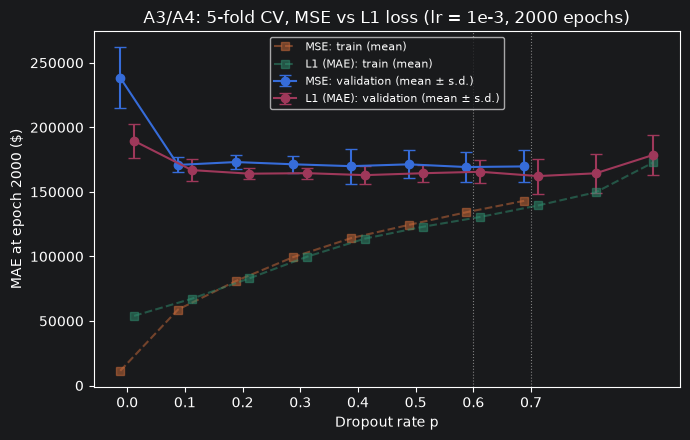

In [35]:
fig, ax = plt.subplots(figsize=(7, 4.5))
offset = 0.012   # shift x-positions so the error bars don't overlap

for table, label, shift in [(a3_table, "MSE", -offset), (a4_table, "L1 (MAE)", offset)]:
    ps = table.index.to_numpy()
    ax.errorbar(ps + shift, table["mean"], yerr=table["s.d."], fmt="o-", capsize=4, label=f"{label}: validation (mean ± s.d.)")
    ax.plot(ps + shift, table["mean train"], "s--", alpha=0.5, label=f"{label}: train (mean)")

for p in [best_p_mse, best_p_l1]:
    ax.axvline(p, ls=":", color="grey", lw=0.8)

ax.set_xticks(a3_table.index)
ax.set_xlabel("Dropout rate p")
ax.set_ylabel("MAE at epoch 2000 ($)")
ax.set_title("A3/A4: 5-fold CV, MSE vs L1 loss (lr = 1e-3, 2000 epochs)")
ax.legend(fontsize=8, loc="upper center")
fig.tight_layout()
fig.savefig("figures/a4_mse_vs_l1.png", dpi=200, bbox_inches="tight")
plt.show()

### A5

- Model: the best configuration from A3/A4 (lowest mean CV MAE over both losses)
- lr: 1e-3, Epochs: 2000
- Training data: all 500 examples, standardizer fitted on all 500
- Test set: used once, here only

In [36]:
if a4_table["mean"].min() < a3_table["mean"].min():
    chosen_loss, chosen_p = "L1", a4_table["mean"].idxmin()
else:
    chosen_loss, chosen_p = "MSE", a3_table["mean"].idxmin()

chosen_cv = (output_l1 if chosen_loss == "L1" else output)[chosen_p][2]
print(f"Chosen: loss={chosen_loss}, p={chosen_p:g}, CV MAE = {chosen_cv.mean():,.0f} ± {chosen_cv.std(ddof=1):,.0f}")

Chosen: loss=L1, p=0.7, CV MAE = 162,241 ± 13,602


In [37]:
def predict(model, standardizer, X):
    # Predictions in dollars for raw (unstandardized) inputs X
    model.eval()
    with torch.no_grad():
        X_standardized = torch.from_numpy(standardizer.transform_X(X).astype(np.float32))
        y_hat = model(X_standardized).squeeze(1)
    return standardizer.inverse(y_hat).numpy()


def mae(y_hat, y):
    return np.mean(np.abs(y_hat.astype(np.float64) - y.astype(np.float64)))

In [38]:
test_df = pd.read_csv("data/housing_2020_test.csv")
X_test = test_df[FEATURES].to_numpy(dtype=np.float32)
y_test = test_df[TARGET].to_numpy(dtype=np.float32)
X_test.shape, y_test.shape

((21282, 6), (21282,))

In [39]:
X_all, y_all, _, _ = split_data(housing_df)

final_model = build_model(p=chosen_p)
final_train_mae, _, final_standardizer = train(final_model, X_all, y_all, None, None, lr=1e-3, epochs=2000, loss_type=chosen_loss)

a5_test_mae = mae(predict(final_model, final_standardizer, X_test), y_test)
print(f"Final train MAE: {final_train_mae[-1]:,.0f}")
print(f"A5 test MAE:     {a5_test_mae:,.0f}   (CV estimate {chosen_cv.mean():,.0f} ± {chosen_cv.std(ddof=1):,.0f})")

Final train MAE: 140,810
A5 test MAE:     162,764   (CV estimate 162,241 ± 13,602)


# Task 1B: Domain adaptation and transfer

### B1


- Provided 1990 MLP (frozen, no training)
- Moment matching: swap the 1990 means / stds for the 2020 ones, computed on the 4 training folds of each CV round
- Compared with: the 1990 network with its own 1990 statistics (no adaptation), and the Task 1A MLP

In [41]:
import json

with open("data/mlp_1990.json") as f:
    info_1990 = json.load(f)

assert [d["name"] for d in info_1990["inputs"]] == FEATURES   # same input order as ours

standardizer_1990 = Standardizer.from_stats(
    mu_x=[d["mean"] for d in info_1990["inputs"]],
    sigma_x=[d["std"] for d in info_1990["inputs"]],
    mu_y=info_1990["price"]["mean"],
    sigma_y=info_1990["price"]["std"],
)

In [42]:
def load_1990_weights(model):
    # The provided state dict has Linear layers at indices 0, 2, 4 (no Dropout layers);
    # in build_model they are at 0, 3, 6.
    state = torch.load("data/mlp_1990.pt")
    index_map = {"0": "0", "2": "3", "4": "6"}
    state = {f"{index_map[k.split('.')[0]]}.{k.split('.')[1]}": v for k, v in state.items()}
    model.load_state_dict(state)
    return model


model_1990 = load_1990_weights(build_model())

In [44]:
check_X = np.array(info_1990["loading_check"]["inputs"], dtype=np.float32)
check_expected = np.array(info_1990["loading_check"]["predicted_price"])
check_pred = predict(model_1990, standardizer_1990, check_X)

print(np.round(check_pred, 1))
print(check_expected)
assert np.allclose(check_pred, check_expected, atol=1.0)

[390712.7 415001.  393730.3 323942.  219832.6]
[390712.  415000.3 393730.1 323942.1 219830.6]


In [45]:
rows = []
for k in range(5):
    X_train, y_train, X_val, y_val = split_data(housing_df, k)
    standardizer_2020 = Standardizer(X_train, y_train)
    rows.append({
        "fold": k,
        "1990 stats (no adaptation)": mae(predict(model_1990, standardizer_1990, X_val), y_val),
        "moment matching": mae(predict(model_1990, standardizer_2020, X_val), y_val),
        f"Task 1A MLP ({chosen_loss}, p={chosen_p:g})": chosen_cv[k],
    })

b1_folds = pd.DataFrame(rows).set_index("fold").round(0)
b1_folds

,1990 stats (no adaptation),moment matching,"Task 1A MLP (L1, p=0.7)"
fold,,,
0,290189.0,196305.0,151725.0
1,290263.0,209274.0,171525.0
2,268152.0,204658.0,152682.0
3,290699.0,198212.0,181666.0
4,264432.0,226799.0,153605.0


In [46]:
b1_table = b1_folds.agg(["mean", "std"]).T.round(0)    # pandas std uses ddof=1, same as before
b1_table["CV MAE ($)"] = [f"{m:,.0f} ± {s:,.0f}" for m, s in zip(b1_table["mean"], b1_table["std"])]

moment_matching_wins = int((b1_folds["moment matching"] < b1_folds.iloc[:, 2]).sum())
print(f"Moment matching beats the Task 1A MLP on {moment_matching_wins}/5 folds")
b1_table

Moment matching beats the Task 1A MLP on 0/5 folds


,mean,std,CV MAE ($)
1990 stats (no adaptation),280747.0,13262.0,"280,747 ± 13,262"
moment matching,207050.0,12189.0,"207,050 ± 12,189"
"Task 1A MLP (L1, p=0.7)",162241.0,13602.0,"162,241 ± 13,602"


### B2

- Fine-tuned: MLP initialised with the 1990 weights, then trained on the 2020 training folds
- Scratch: same architecture with PyTorch default initialisation
- Both use the chosen Task 1A settings (loss, p, 2000 epochs) and the 2020 standardizer of each fold,
  so the fine-tuned model starts exactly from the moment-matched network of B1
- Two learning rates: 1e-3 (as in Task 1A) and 1e-4 (smaller steps, so less of the 1990 knowledge is overwritten)

In [47]:
b2_lrs = [1e-3, 1e-4]

output_b2 = {}

for lr in b2_lrs:
    output_b2["fine-tuned", lr] = cross_validate(chosen_p, lr=lr, epochs=2000, loss_type=chosen_loss, pretrained=True)
    output_b2["scratch", lr] = cross_validate(chosen_p, lr=lr, epochs=2000, loss_type=chosen_loss)

In [48]:
rows = []
for (init, lr), (train_curves, val_curves, final_val) in output_b2.items():
    mean_val = val_curves.mean(axis=0)
    scratch_final = output_b2["scratch", lr][2]
    rows.append({
        "init": init,
        "lr": lr,
        "val MAE after 1 epoch": mean_val[0],
        "best mean val MAE": mean_val.min(),
        "epoch of best": int(np.argmin(mean_val)),
        "mean": final_val.mean(),
        "s.d.": final_val.std(ddof=1),
        "mean train": train_curves[:, -1].mean(),
        "folds beating scratch": int((final_val < scratch_final).sum()) if init == "fine-tuned" else None,
    })

b2_table = pd.DataFrame(rows).set_index(["lr", "init"]).sort_index().round(0)
b2_table

val MAE after 1 epoch  best mean val MAE  epoch of best  \
lr     init                                                                  
0.0001 fine-tuned               206867.0           201595.0             46   
       scratch                  301592.0           177472.0           1999   
0.0010 fine-tuned               206938.0           177707.0           1992   
       scratch                  297586.0           161412.0           1124   

                       mean     s.d.  mean train  folds beating scratch  
lr     init                                                              
0.0001 fine-tuned  310627.0   8072.0    310181.0                    0.0  
       scratch     177472.0  15264.0    172622.0                    NaN  
0.0010 fine-tuned  178237.0  15415.0    170870.0                    0.0  
       scratch     162241.0  13602.0    139473.0                    NaN

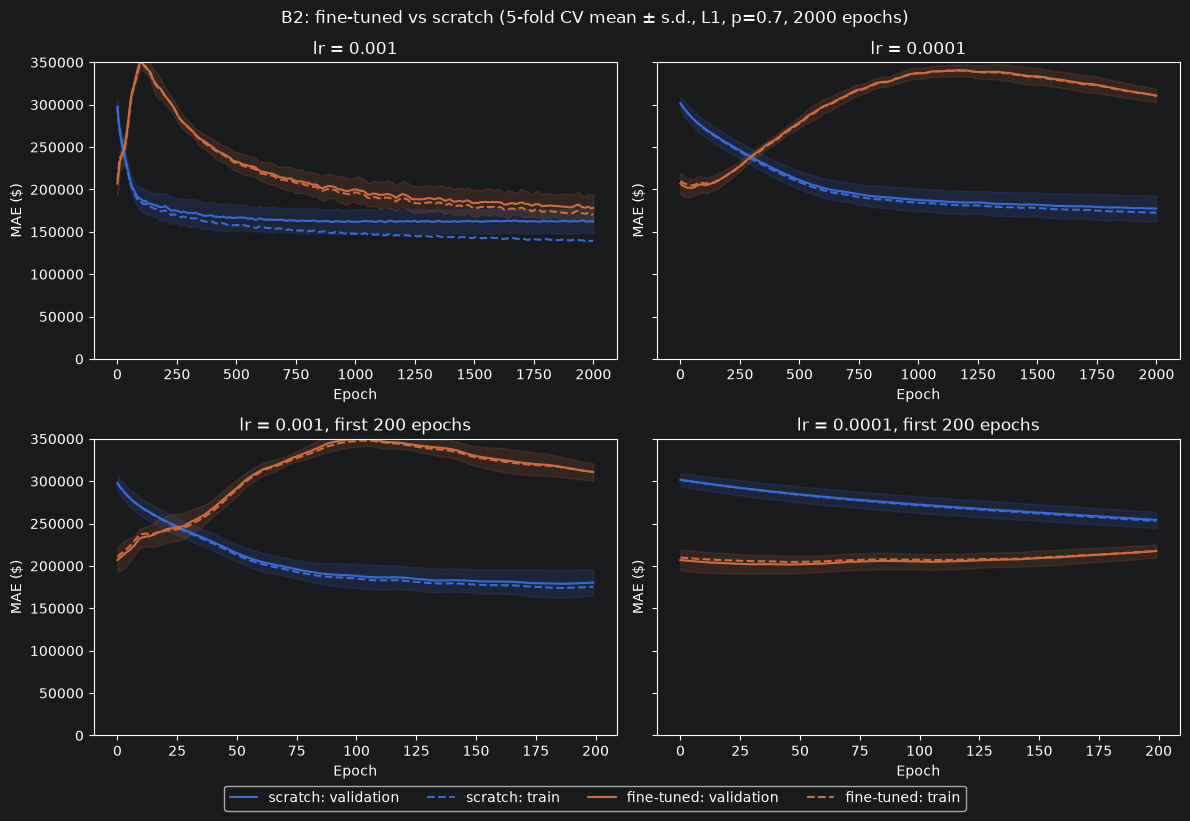

In [49]:
fig, axes = plt.subplots(2, len(b2_lrs), figsize=(6 * len(b2_lrs), 8), sharey=True)

for col, lr in enumerate(b2_lrs):
    for row, zoom in enumerate([False, True]):        # full run, and a zoom on the first 200 epochs
        ax = axes[row, col]
        for init, color in [("scratch", "C0"), ("fine-tuned", "C1")]:
            train_curves, val_curves, _ = output_b2[init, lr]
            max_epoch = min(200, val_curves.shape[1]) if zoom else val_curves.shape[1]
            epochs = np.arange(max_epoch)
            mean_val = val_curves.mean(axis=0)[:max_epoch]
            sd_val = val_curves.std(axis=0, ddof=1)[:max_epoch]
            ax.plot(epochs, mean_val, color=color, label=f"{init}: validation")
            ax.fill_between(epochs, mean_val - sd_val, mean_val + sd_val, color=color, alpha=0.15)
            ax.plot(epochs, train_curves.mean(axis=0)[:max_epoch], color=color, ls="--", label=f"{init}: train")
        ax.set_title(f"lr = {lr:g}" + (", first 200 epochs" if zoom else ""))
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE ($)")
        ax.set_ylim(0, 350_000)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle(f"B2: fine-tuned vs scratch (5-fold CV mean ± s.d., {chosen_loss}, p={chosen_p:g}, 2000 epochs)")
fig.tight_layout()
fig.savefig("figures/b2_finetune_vs_scratch.png", dpi=200, bbox_inches="tight")
plt.show()